<a href="https://colab.research.google.com/github/SattikBhaumik/CS156/blob/main/CS156_Session_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Max Likelihood 1: Naive Bayes

In [1]:
# load in dataset
import pandas as pd
from sklearn.feature_extraction import text
df = pd.read_csv("https://raw.githubusercontent.com/milindsoorya/Spam-Classifier-in-python/main/dataset/spam.csv", encoding='latin-1')
labels, texts = df['v1'], df['v2']
vectorizer = text.TfidfVectorizer()
vec_texts = vectorizer.fit_transform(texts)

# Uncomment and print one at a time
#print(texts[:3])
# Hint: vec_texts is a sparse matrix; the coordinates are only shown for its "nonzero" entries
#print(vec_texts[:3], vec_texts[:3].shape)
#print(vectorizer.vocabulary_)

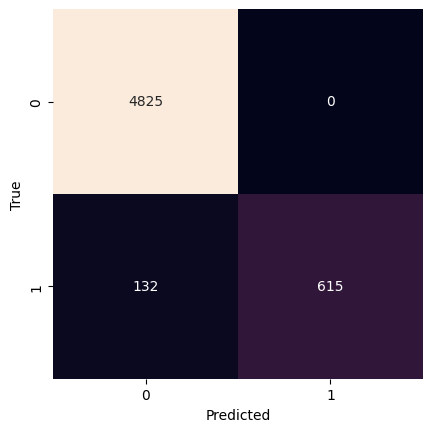

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import metrics, naive_bayes

# We train a model
model = naive_bayes.MultinomialNB()
model.fit(vec_texts, labels)
pred_labels = model.predict(vec_texts)

confusion_mat = metrics.confusion_matrix(labels, pred_labels)
sns.heatmap(confusion_mat, square=True, annot=True, fmt='d', cbar=False)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

In [3]:
# See your hints!
#print(vectorizer.vocabulary_)
print(model.feature_log_prob_)

[[-10.06949321 -10.06949321  -9.86049521 ... -10.06949321  -8.82965554
   -9.76211664]
 [ -8.21151797  -7.37661278  -9.38713898 ...  -9.13325442  -9.38713898
   -9.38713898]]


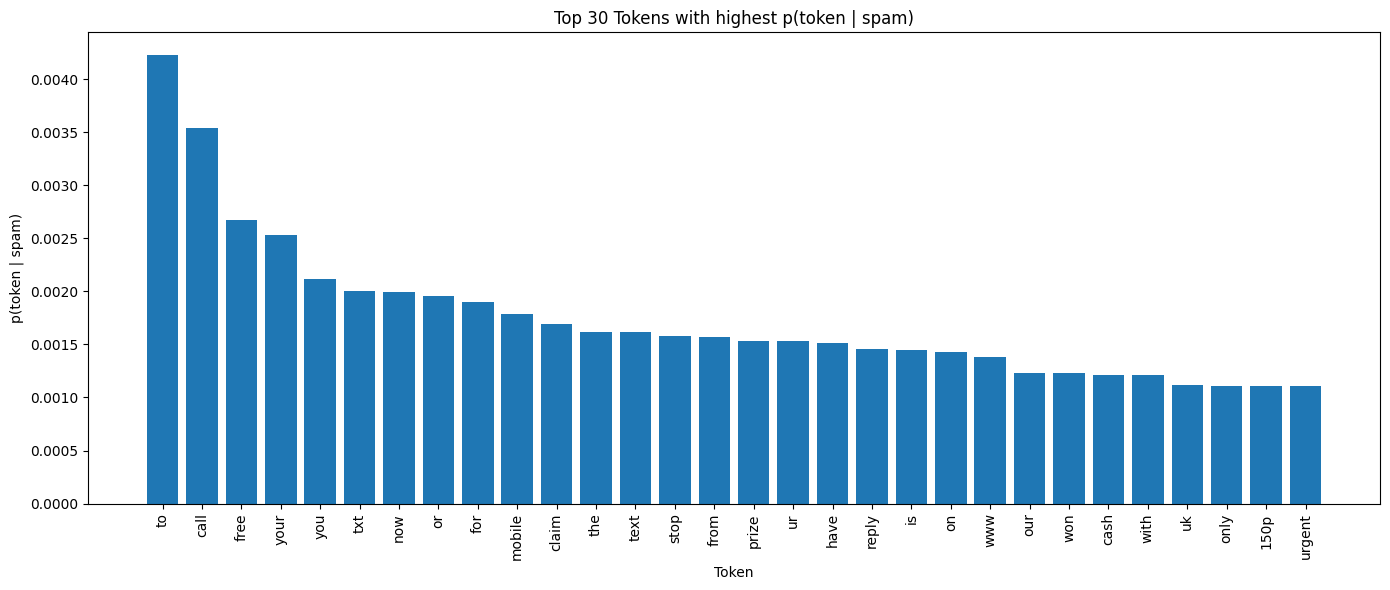

In [6]:
'''
of the top 30 "tokens" with the highest p(X|"spam"), where X is the token itself.
the Y value should be the p(X|"spam") value
sort the tokens on the X axis descending on their Y value (largest first)
'''

## I used google AI to search for the scikit-learn method since I got a bit confused with the documentations but with the help of Google search, I immediately understood where I was going wrong
## I used claude to refine the code further
## comments are my own

import numpy as np
import matplotlib.pyplot as plt

# following the labeling of the confusion matrix plot
spam_index = 1

# scikit-learn method
tokens = [None] * len(vectorizer.vocabulary_)
for token, index in vectorizer.vocabulary_.items():
    tokens[index] = token

# log probabilities ---> probabilities
spam_probs = np.exp(model.feature_log_prob_[spam_index])

# each token with p(token | spam) :: p(X|"spam")
token_probs = list(zip(tokens, spam_probs))

# top 30 highest probabilities
top_30 = sorted(token_probs, key=lambda x: x[1], reverse=True)[:30]
top_tokens = [x[0] for x in top_30]
top_probs = [x[1] for x in top_30]

plt.figure(figsize=(14, 6))
plt.bar(top_tokens, top_probs)
plt.xlabel("Token")
plt.ylabel("p(token | spam)")
plt.title("Top 30 Tokens with highest p(token | spam)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

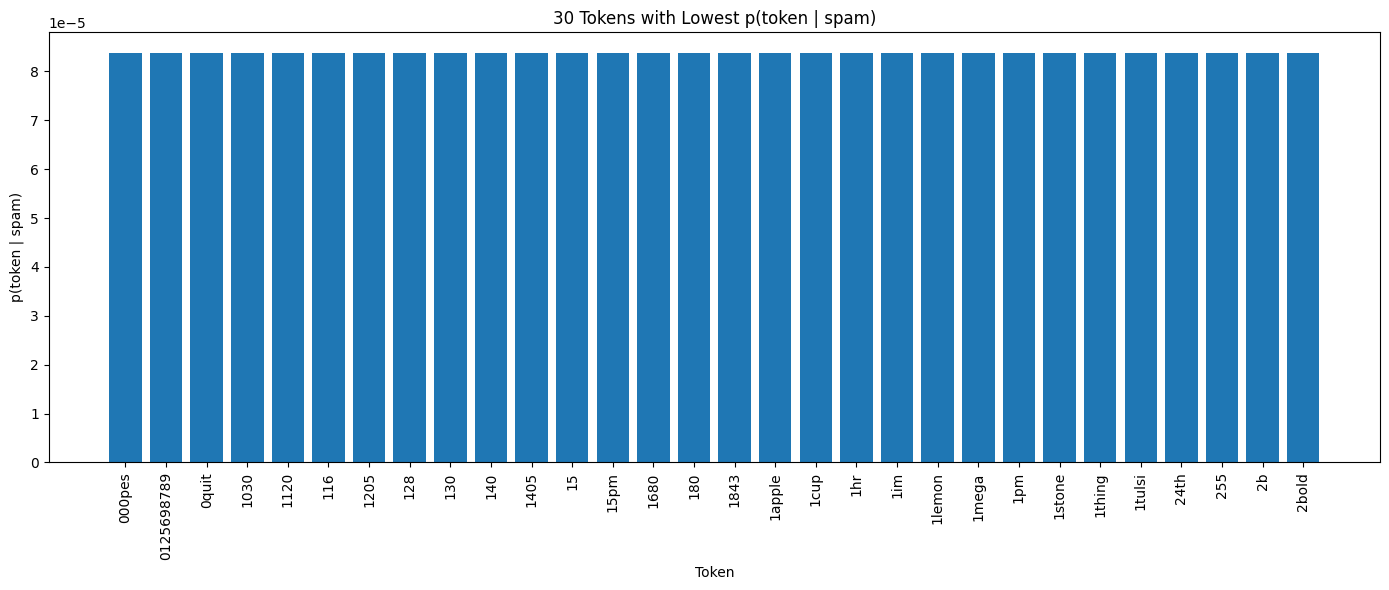

In [7]:
# lowest 30 lowest probabilities
lowest_30 = sorted(token_probs, key=lambda x: x[1])[:30]
# sorting and plotting largest-to-smallest among the lowest 30
lowest_30 = sorted(lowest_30, key=lambda x: x[1], reverse=True)
lowest_tokens = [x[0] for x in lowest_30]
lowest_probs = [x[1] for x in lowest_30]

plt.figure(figsize=(14, 6))
plt.bar(lowest_tokens, lowest_probs)
plt.xlabel("Token")
plt.ylabel("p(token | spam)")
plt.title("30 Tokens with Lowest p(token | spam)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()